# The Jacobian lens on Mamba-130m, with TorchLens

Each block of a language model passes a residual vector per token to the next block. The Jacobian lens (Gurnee et al., 2026) scores vocabulary tokens associated with a block's residual vector: it carries the vector into the final block's basis with one fixed matrix per block, the corpus-average Jacobian of the final block's output with respect to that block's output, and then applies the model's own final norm and unembedding. The logit lens is the special case where every matrix is the identity.

$$\mathrm{lens}_l(h) = \mathrm{unembed}\big(\mathrm{norm}_f(J_l\,h)\big), \qquad J_l = \mathbb{E}\left[\frac{\partial h_{L}}{\partial h_l}\right]$$

This notebook fits the lens for Mamba-130m, a state-space model with no attention, and reads all 24 layers on four prompts. The paper's reference implementation adapts Hugging Face models through a fixed set of recognized model layouts, and Mamba is outside them, so the reference code cannot fit this model. TorchLens needs no registered adapter for Mamba: one trace per sentence captures the named blocks, and ordinary PyTorch computes the Jacobians. The last section compares the fitted rows with exact scalar autograd and prints the relative error.

Run all. The tested path is the CPU: the model download is about 500 MB, and on a two-core CPU the whole notebook took between two and eight minutes in our runs (the fit prints its own time). The notebook runs on the CPU even on a GPU runtime; a GPU path has not been tested.

Paper: Gurnee et al., "Verbalizable Representations Form a Global Workspace in Language Models", Transformer Circuits, July 2026, https://transformer-circuits.pub/2026/workspace/index.html

In [ ]:
from importlib.metadata import PackageNotFoundError, version


def at_least(package, floor):
    try:
        have = tuple(int(part) for part in version(package).split(".")[: len(floor)])
    except (PackageNotFoundError, ValueError):
        return False
    return have >= floor


if not (
    at_least("torchlens", (3, 0, 2))
    and at_least("transformers", (5, 18))
    and at_least("matplotlib", (3, 5))
):
    %pip install -q "torchlens>=3.0.2" "transformers>=5.18" "matplotlib>=3.5"

In [ ]:
import functools
import time

import torch
from transformers import AutoTokenizer, MambaForCausalLM, logging

import torchlens as tl

logging.set_verbosity_error()  # Mamba on CPU takes the plain PyTorch path, and transformers says so at length
device = "cpu"  # the tested path; the notebook runs on the CPU even on a GPU runtime

MODEL_ID = "state-spaces/mamba-130m-hf"
REVISION = "1e76775f628fbf1350fbe4dbb3d971ba64af25a1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = (
    MambaForCausalLM.from_pretrained(MODEL_ID, revision=REVISION, use_cache=False).eval().to(device)
)

layers = [f"backbone.layers.{i}" for i in range(len(model.backbone.layers))]
final_norm, unembed = model.backbone.norm_f, model.lm_head
d_model = model.config.hidden_size
print(
    f"{len(layers)} layers, d_model = {d_model}, TorchLens {tl.__version__}, torch {torch.__version__}, {device}"
)

24 layers, d_model = 768, TorchLens 3.0.3, torch 2.15.0+cpu, cpu


## The TorchLens part

`tl.trace(model, ids, capture=CaptureOptions(save_mode="view"))` runs one forward pass and keeps every block's live output on the autograd graph (the default mode saves copies, which have no path back to the model's computation). `trace["backbone.layers.7"].out` is then the actual residual tensor that block 8 consumed, so `torch.autograd.grad` can differentiate the final block's output with respect to it.

The estimator is the one in the TorchLens gallery entry. For each sentence, the final block's output is summed over positions 1 to T-2 (the first and the last token are left out), and a block of cotangents (output directions, `CHUNK` at a time) gives that many Jacobian rows for every earlier block in one backward pass. The rows are averaged over the same source positions, then over sentences with equal weight. Nothing here is specific to Mamba beyond the module names.

In [ ]:
CORPUS = [
    "The cat sat on the mat while rain fell outside.",
    "A little boat crossed the lake before the sun went down.",
]
SKIP_FIRST = 1  # positions skipped at the start of each sentence
CHUNK = 4  # cotangents per backward pass; on Mamba's CPU path larger blocks gain nothing


def residual_states(ids):
    trace = tl.trace(model, ids, capture=tl.options.CaptureOptions(save_mode="view"))
    return [trace[name].out for name in layers]


@functools.cache
def prompt_jacobians(text):
    # One sentence's Jacobian rows for every earlier block, averaged over its source positions.
    states = residual_states(tokenizer(text, return_tensors="pt").input_ids.to(device))
    target = states[-1][0, SKIP_FIRST:-1].sum(0)
    rows = [[] for _ in layers[:-1]]
    for cotangents in torch.eye(d_model, device=device).split(CHUNK):
        grads = torch.autograd.grad(
            target, states[:-1], grad_outputs=cotangents, is_grads_batched=True, retain_graph=True
        )
        for row_list, grad in zip(rows, grads):
            row_list.append(grad[:, 0, SKIP_FIRST:-1].mean(1).detach())
    return [torch.cat(row_list) for row_list in rows]


def fit_jacobian_lens(texts):
    # Corpus-average Jacobian of the final block's output with respect to each earlier block's.
    per_prompt = [prompt_jacobians(text) for text in texts]
    return [sum(rows[i] for rows in per_prompt) / len(texts) for i in range(len(layers) - 1)]


started = time.perf_counter()
J = fit_jacobian_lens(CORPUS)
print(
    f"fitted {len(J)} matrices of shape {tuple(J[0].shape)} in {time.perf_counter() - started:.0f} s"
)

fitted 23 matrices of shape (768, 768) in 370 s


## Reading every layer on four prompts

The readout is the paper's: transport the last position's residual with $J_l$, then apply Mamba's final norm and unembedding. Each cell below is a lens's top token at that layer; layer 23 is the model's own output, so both lenses agree there by construction. Darker cells give more probability to the model's final token, so the shading tracks agreement with the model, not confidence in the printed token.

On these four prompts, chosen from twenty we tried, the Jacobian lens reads Paris and cold from layer 20, where the logit lens still gives commas and function words; the logit lens reaches those two words at layer 22. On the two prompts where the model itself answers " the", the Jacobian lens reads " France" from layer 19, and " Jupiter", " Saturn", " Jupiter" at layers 20 to 22. These are the top tokens of a two-sentence fit on four selected prompts, not a measurement of the lens's accuracy.

The second figure shows all 24 layers. Below layer 19 the Jacobian-lens readouts are mostly fragments: byte pieces ("��" is the tokenizer's replacement glyph), symbols and subword pieces such as "openhagen". A larger, representative corpus may change them; in our runs eight sentences did not.

In [ ]:
# @title Readout and figure helpers (plain PyTorch and matplotlib)
import io
import textwrap

import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.colors import Normalize
from PIL import Image as PILImage


def lens_probs(h, matrix=None):
    with torch.no_grad():
        return torch.softmax(unembed(final_norm(h if matrix is None else h @ matrix.T)), -1)


def read_prompt(text):
    ids = tokenizer(text, return_tensors="pt").input_ids.to(device)
    with torch.no_grad():
        states = [h[0, -1].detach() for h in residual_states(ids)]
    answer = int(lens_probs(states[-1]).argmax())
    out = {"answer": tokenizer.decode(answer)}
    for name, matrices in (("Jacobian lens", J + [None]), ("logit lens", [None] * len(layers))):
        probs = [lens_probs(h, m) for h, m in zip(states, matrices)]
        out[name] = [
            (tokenizer.decode(int(p.argmax())), float(p.max()), float(p[answer])) for p in probs
        ]
    return out


def show_png(path, width):
    # Display a palette-quantized copy so the stored notebook stays small; the file on disk is full colour.
    buffer = io.BytesIO()
    PILImage.open(path).quantize(colors=96).save(buffer, "PNG", optimize=True)
    display(Image(data=buffer.getvalue(), width=width))


CMAP, NORM = plt.get_cmap("Blues"), Normalize(0, 1)


def show(token, limit=14):
    text = token.strip()
    return text[:limit] if text else "(space)"


def fill_panel(ax, readouts, prompts, layers_shown, name, font, headers=True):
    # One row per layer, one column per prompt; text is the lens's top token, shade its probability
    # for the model's final token.
    for col, text in enumerate(prompts):
        for row, layer in enumerate(layers_shown):
            token, p_top, p_answer = readouts[text][name][layer]
            ax.add_patch(
                plt.Rectangle(
                    (col, row),
                    1,
                    1,
                    facecolor=CMAP(NORM(p_answer)),
                    edgecolor="white",
                    linewidth=0.8,
                )
            )
            ax.text(
                col + 0.5,
                row + 0.5,
                show(token),
                ha="center",
                va="center",
                fontsize=font,
                color="white" if p_answer > 0.6 else "#1f1f1e",
                family="monospace",
            )
    ax.set_xlim(0, len(prompts))
    ax.set_ylim(len(layers_shown), 0)
    ax.set_xticks([c + 0.5 for c in range(len(prompts))])
    if headers:
        ax.set_xticklabels(
            [f"{textwrap.fill(t, 17)}\nmodel: {show(readouts[t]['answer'])}" for t in prompts],
            fontsize=font,
            linespacing=1.1,
        )
        ax.xaxis.tick_top()
    else:
        ax.set_xticklabels([])
    ax.set_yticks([r + 0.5 for r in range(len(layers_shown))])
    ax.set_yticklabels([f"layer {layer}" for layer in layers_shown], fontsize=font)
    ax.tick_params(length=0, pad=4)
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)


def finish(fig, axes, title, notes, font, title_font, title_y, step):
    cbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=NORM, cmap=CMAP), ax=axes, fraction=0.025, pad=0.015
    )
    cbar.set_label("lens probability of the header's model token", fontsize=font)
    cbar.ax.tick_params(labelsize=font)
    fig.text(0.012, title_y, title, fontsize=title_font, fontweight="bold", va="bottom")
    for k, line in enumerate(notes):
        fig.text(0.012, title_y - step * (k + 1), line, fontsize=font, va="bottom")


def draw_stacked(readouts, prompts, layers_shown, title, notes, path=None):
    # Main figure: 760 px wide at 2x; the two lenses stacked, column headers drawn once.
    n, font = len(layers_shown), 11
    notes = [line for note in notes for line in textwrap.wrap(note, 84)]
    row_in, top_in, head_in, gap_in = 0.26, 0.42 + 0.19 * len(notes), 0.95, 0.42
    height = top_in + head_in + 2 * n * row_in + gap_in + 0.12
    fig = plt.figure(figsize=(7.6, height), dpi=200)
    left, width = 0.11, 0.775
    panel_h = n * row_in / height
    top_ax = fig.add_axes([left, 1 - (top_in + head_in) / height - panel_h, width, panel_h])
    low_ax = fig.add_axes([left, 0.12 / height, width, panel_h])
    fill_panel(top_ax, readouts, prompts, layers_shown, "Jacobian lens", font)
    fill_panel(low_ax, readouts, prompts, layers_shown, "logit lens", font, headers=False)
    top_ax.set_title("Jacobian lens", loc="left", fontsize=font + 2, fontweight="bold", pad=10)
    low_ax.set_title("logit lens", loc="left", fontsize=font + 2, pad=6)
    finish(fig, [top_ax, low_ax], title, notes, font, 13, 1 - 0.28 / height, 0.19 / height)
    if path:
        fig.savefig(path, dpi=200, facecolor="white")
    return fig


def draw_wide(readouts, prompts, layers_shown, title, notes, path=None):
    # Detail figure: 1920 x 1080, the two lenses side by side, every layer.
    font, step, title_y = 15, 0.026, 0.955
    notes = [line for note in notes for line in textwrap.wrap(note, 150)]
    fig, axes = plt.subplots(1, 2, figsize=(19.2, 10.8), dpi=100, sharey=True)
    fig.subplots_adjust(
        left=0.075,
        right=0.915,
        top=title_y - step * (len(notes) + 1) - 0.125,
        bottom=0.02,
        wspace=0.06,
    )
    for ax, name in zip(axes, ("Jacobian lens", "logit lens")):
        fill_panel(ax, readouts, prompts, layers_shown, name, font)
        ax.set_title(
            name,
            loc="left",
            fontsize=font + 2,
            pad=10,
            fontweight="bold" if name == "Jacobian lens" else "normal",
        )
    axes[1].tick_params(labelleft=False)
    finish(fig, axes, title, notes, font, 21, title_y, step)
    if path:
        fig.savefig(path, dpi=100, facecolor="white")
    return fig

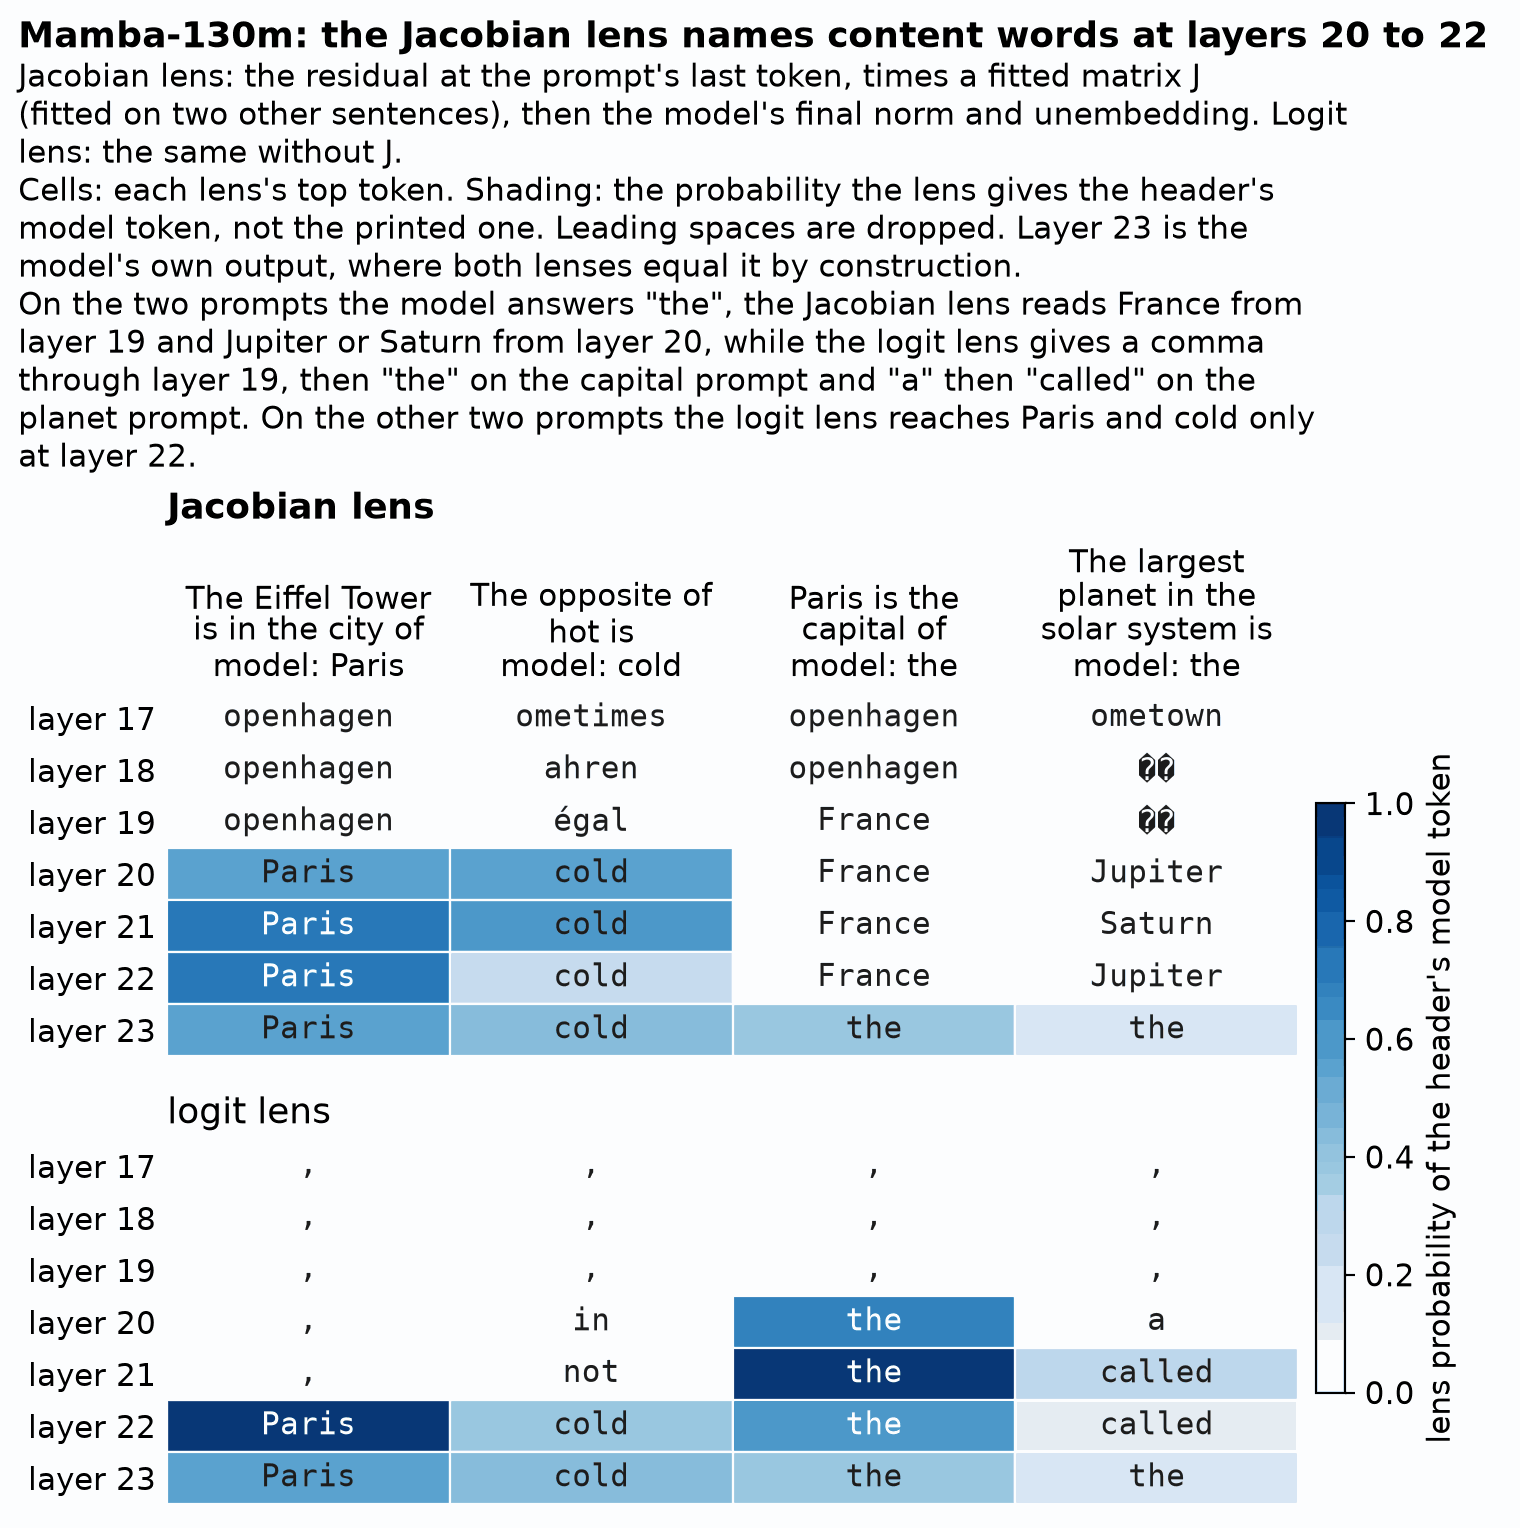

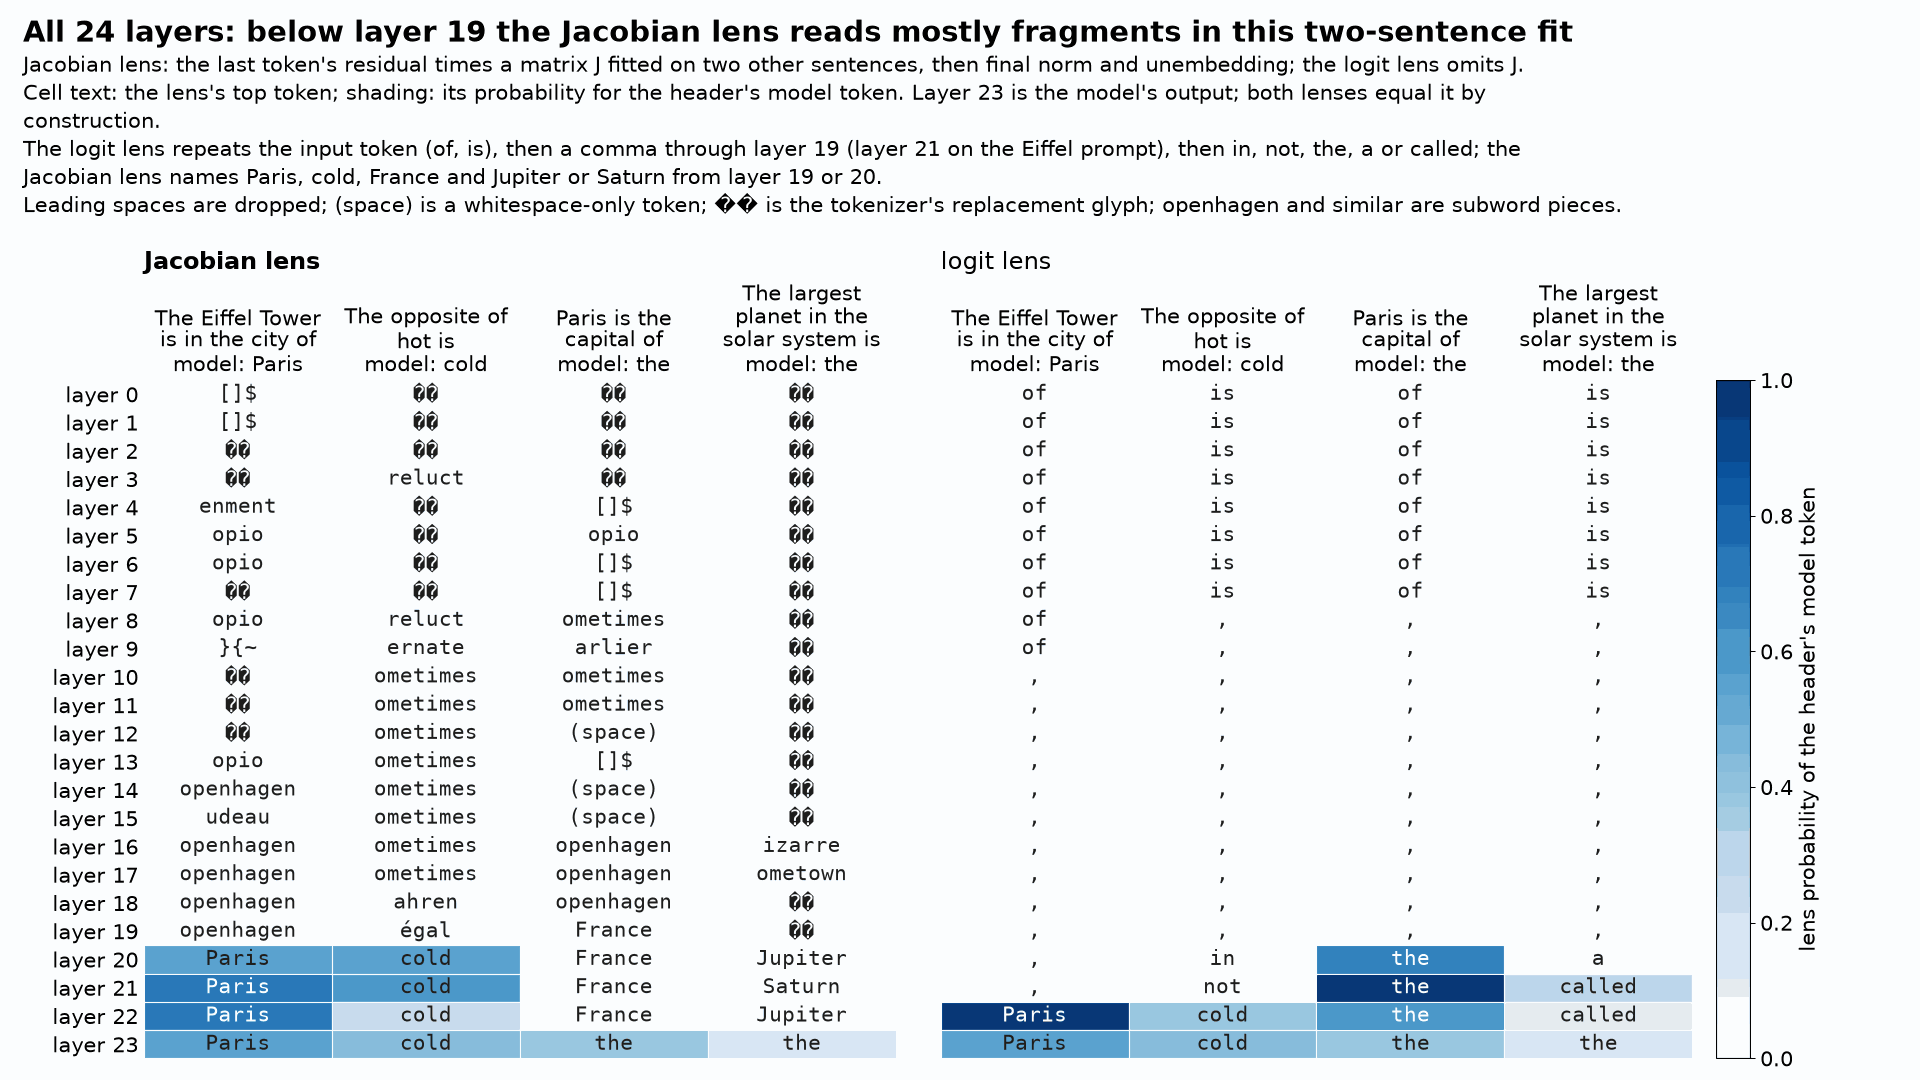

In [ ]:
TITLE_LATE = "Mamba-130m: the Jacobian lens names content words at layers 20 to 22"
NOTES_LATE = [
    "Jacobian lens: the residual at the prompt's last token, times a fitted matrix J (fitted on two other sentences), then the model's final norm and unembedding. Logit lens: the same without J.",
    "Cells: each lens's top token. Shading: the probability the lens gives the header's model token, not the printed one. Leading spaces are dropped. Layer 23 is the model's own output, where both lenses equal it by construction.",
    'On the two prompts the model answers "the", the Jacobian lens reads France from layer 19 and Jupiter or Saturn from layer 20, while the logit lens gives a comma through layer 19, then "the" on the capital prompt and "a" then "called" on the planet prompt. On the other two prompts the logit lens reaches Paris and cold only at layer 22.',
]
TITLE_ALL = "All 24 layers: below layer 19 the Jacobian lens reads mostly fragments in this two-sentence fit"
NOTES_ALL = [
    "Jacobian lens: the last token's residual times a matrix J fitted on two other sentences, then final norm and unembedding; the logit lens omits J.",
    "Cell text: the lens's top token; shading: its probability for the header's model token. Layer 23 is the model's output; both lenses equal it by construction.",
    "The logit lens repeats the input token (of, is), then a comma through layer 19 (layer 21 on the Eiffel prompt), then in, not, the, a or called; the Jacobian lens names Paris, cold, France and Jupiter or Saturn from layer 19 or 20.",
    "Leading spaces are dropped; (space) is a whitespace-only token; \ufffd\ufffd is the tokenizer's replacement glyph; openhagen and similar are subword pieces.",
]

PROMPTS = [
    "The Eiffel Tower is in the city of",
    "The opposite of hot is",
    "Paris is the capital of",
    "The largest planet in the solar system is",
]
readouts = {text: read_prompt(text) for text in PROMPTS}

draw_stacked(
    readouts, PROMPTS, list(range(17, 24)), TITLE_LATE, NOTES_LATE, path="mamba_lens_late.png"
)
draw_wide(
    readouts,
    PROMPTS,
    list(range(len(layers))),
    TITLE_ALL,
    NOTES_ALL,
    path="mamba_lens_all_layers.png",
)
plt.close("all")
show_png("mamba_lens_late.png", 760)
show_png("mamba_lens_all_layers.png", 960)

## Spot-check the per-sentence Jacobians against exact autograd

Nothing here uses TorchLens. Plain forward hooks catch the block outputs, and `torch.autograd.grad` on one scalar output at a time gives exact Jacobian rows, reduced the same way as the fit. Scalar reverse mode through Mamba's sequential scan is slow, so this check takes the first 64 of the 768 rows at three blocks for one corpus sentence and compares them with the TorchLens rows for that same sentence (cached during the fit). It prints its own error: on an x86 CPU the batched and scalar passes differ by float32 round-off, about 1e-7; on Apple silicon in our run they agreed exactly. The full comparison, every row of all 23 matrices of the two-sentence fit against the same scalar oracle, is the TorchLens gallery entry linked below, where the largest relative error was 4.8e-7 (layer 0) and the smallest 4.8e-8 (layer 22). The two checks have different scopes, so their numbers are not expected to match.

In [ ]:
CHECK_LAYERS, CHECK_ROWS = (0, 11, 22), 64
text = CORPUS[0]
ids = tokenizer(text, return_tensors="pt").input_ids.to(device)

seen = {}
handles = [
    model.backbone.layers[i].register_forward_hook(
        lambda module, args, out, i=i: seen.__setitem__(
            i, out[0] if isinstance(out, tuple) else out
        )
    )
    for i in range(len(layers))
]
model(ids, use_cache=False)
for handle in handles:
    handle.remove()

target = seen[len(layers) - 1][0, SKIP_FIRST:-1].sum(0)
sources = [seen[i] for i in CHECK_LAYERS]
started = time.perf_counter()
exact = {i: [] for i in CHECK_LAYERS}
for value in target[:CHECK_ROWS]:
    for i, grad in zip(CHECK_LAYERS, torch.autograd.grad(value, sources, retain_graph=True)):
        exact[i].append(grad[0, SKIP_FIRST:-1].mean(0).detach())
print(
    f"{CHECK_ROWS} exact rows at {len(CHECK_LAYERS)} blocks in {time.perf_counter() - started:.0f} s"
)

captured = prompt_jacobians(text)  # the TorchLens rows for the same sentence, cached from the fit
for i in CHECK_LAYERS:
    reference = torch.stack(exact[i])
    error = float((captured[i][:CHECK_ROWS] - reference).norm() / reference.norm())
    print(f"block {i:>2}: relative Frobenius error {error:.1e}")

64 exact rows at 3 blocks in 16 s
block  0: relative Frobenius error 6.0e-07
block 11: relative Frobenius error 3.5e-07
block 22: relative Frobenius error 5.5e-08


## Notes

- The corpus is two sentences, so the matrices are a demonstration of the mechanics, not a fit of the paper's dataset. Add sentences to `CORPUS` to try a larger fit; the cost grows linearly, about 768 scalar-equivalent backward passes per sentence on a CPU.
- `save_mode="view"` keeps live tensors. A model that overwrote its residual stream in place would change the saved state; `save_mode="reference"` raises on a read after such a write.
- The fit runs with gradients on; only the readouts and the figures run under `torch.no_grad()`.

TorchLens: https://github.com/johnmarktaylor91/torchlens. The checked gallery entry with GPT-2 small against the paper's reference code and Mamba-130m against exact autograd over all 23 layers: https://github.com/johnmarktaylor91/torchlens/blob/main/docs/gallery/jacobian_lens.md. A step-by-step GPT-2 version of this recipe: https://github.com/johnmarktaylor91/torchlens/blob/main/examples/methods/jacobian_lens_recipe.ipynb.